# What users complain about in India's top UPI apps
Google Play reviews of **PhonePe, Google Pay and Paytm** (English, India store), scraped with `google-play-scraper`, cleaned into SQLite and analysed with SQL (`sql/queries.sql`).

**Questions**
1. How do the three apps compare on rating, and how has that changed over time?
2. What do unhappy users complain about, and does it differ by app?
3. Which app versions coincided with a drop in rating?
4. Which issues hurt the rating most?
5. How well do the developers respond to negative reviews?

In [1]:
import sys, sqlite3
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
import plotly.express as px
import plotly.io as pio
from config import DB_PATH, FIG_DIR, COMPLAINT_THEMES
from sqlq import run
pio.renderers.default = 'png'
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {'PhonePe': '#5f259f', 'Google Pay': '#1a73e8', 'Paytm': '#00b9f1'}
pd.set_option('display.max_colwidth', 160)
def save(fig, name):
    fig.update_layout(template='plotly_white', width=1000, height=520)
    fig.write_image(FIG_DIR / f'{name}.png', scale=2)
    return fig

## 1. Data overview and quality checks

In [2]:
with sqlite3.connect(DB_PATH) as con:
    checks = pd.read_sql('''SELECT COUNT(*) AS rows, COUNT(DISTINCT review_id) AS unique_ids,
        SUM(rating IS NULL) AS null_ratings, SUM(content IS NULL OR content = '') AS empty_text,
        ROUND(AVG(is_english), 3) AS share_english, MIN(review_date) AS first, MAX(review_date) AS last
        FROM reviews''', con)
checks

,rows,unique_ids,null_ratings,empty_text,share_english,first,last
0,90000,90000,0,0,0.815,2026-09-04,2026-11-19


In [3]:
run('coverage')

,app,reviews,first_day,last_day,reviews_per_day,pct_under_3_words
0,Google Pay,30000,2026-11-13,2026-11-19,4286.0,78.8
1,Paytm,30000,2026-09-04,2026-11-19,390.0,72.1
2,PhonePe,30000,2026-09-17,2026-11-19,469.0,69.5


**Coverage differs by app.** Each app has 30k reviews, but Google Pay gets far more reviews per day, so its 30k span only about a week. Rating comparisons between apps therefore use only the dates all three cover (`in_common_window = 1`). Theme shares use each app's full sample.

In [4]:
summary = run('app_summary'); summary

,app,reviews,avg_rating,pct_one_star,pct_five_star,pct_replied,first_review,last_review
0,Paytm,2153,4.67,6.0,87.8,96.1,2026-11-14,2026-11-19
1,Google Pay,28394,4.58,4.4,78.6,1.6,2026-11-14,2026-11-19
2,PhonePe,2022,4.34,10.5,72.7,24.4,2026-11-14,2026-11-19


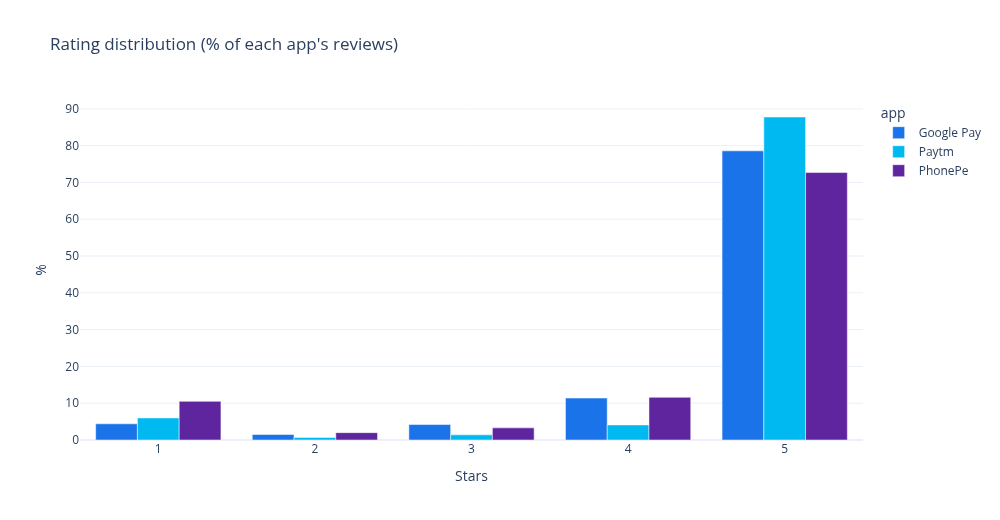

In [5]:
dist = run('rating_distribution')
save(px.bar(dist, x='rating', y='pct', color='app', barmode='group', color_discrete_map=COLORS,
            title='Rating distribution (% of each app\'s reviews)', labels={'pct': '%', 'rating': 'Stars'}),
     'rating_distribution')

Play Store reviews are **J-shaped**: mostly 5★ and 1★. Reviews are written by users who feel strongly, so they measure *what goes wrong*, not overall satisfaction.

## 2. Rating over time

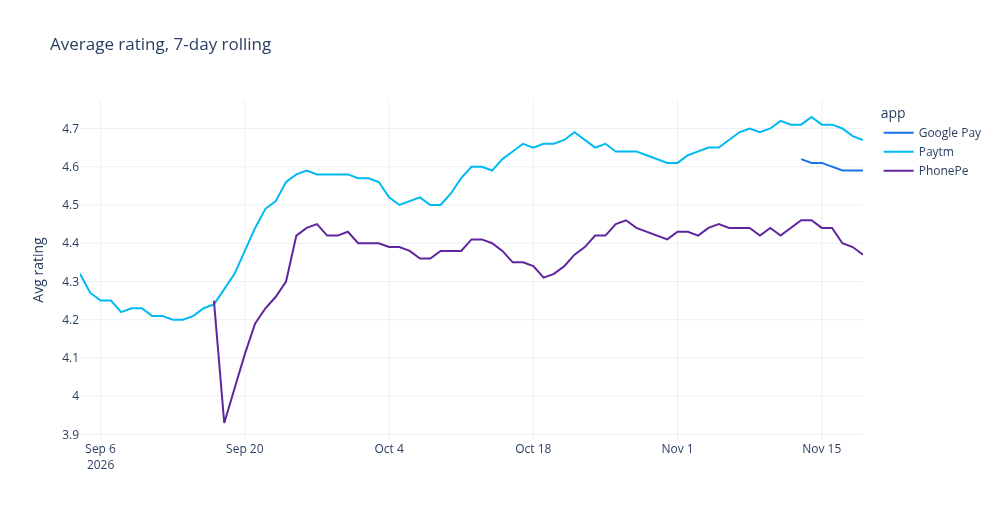

In [6]:
trend = run('daily_trend')
save(px.line(trend, x='review_date', y='rolling_7d', color='app', color_discrete_map=COLORS,
             title='Average rating, 7-day rolling', labels={'rolling_7d': 'Avg rating', 'review_date': ''}),
     'daily_trend')

In [7]:
trend.sort_values('pct_one_star', ascending=False).head(8)

,app,review_date,reviews,avg_rating,pct_one_star,rolling_7d
85,PhonePe,2026-09-18,632,3.61,31.2,3.93
11,Paytm,2026-09-08,388,4.12,18.3,4.22
14,Paytm,2026-09-11,380,4.14,17.9,4.21
16,Paytm,2026-09-13,402,4.19,16.7,4.20
15,Paytm,2026-09-12,471,4.20,15.5,4.21
8,Paytm,2026-09-05,382,4.21,15.4,4.27
86,PhonePe,2026-09-19,534,4.20,15.0,4.02
10,Paytm,2026-09-07,525,4.23,15.0,4.25


## 3. What do 1–2★ reviews complain about?

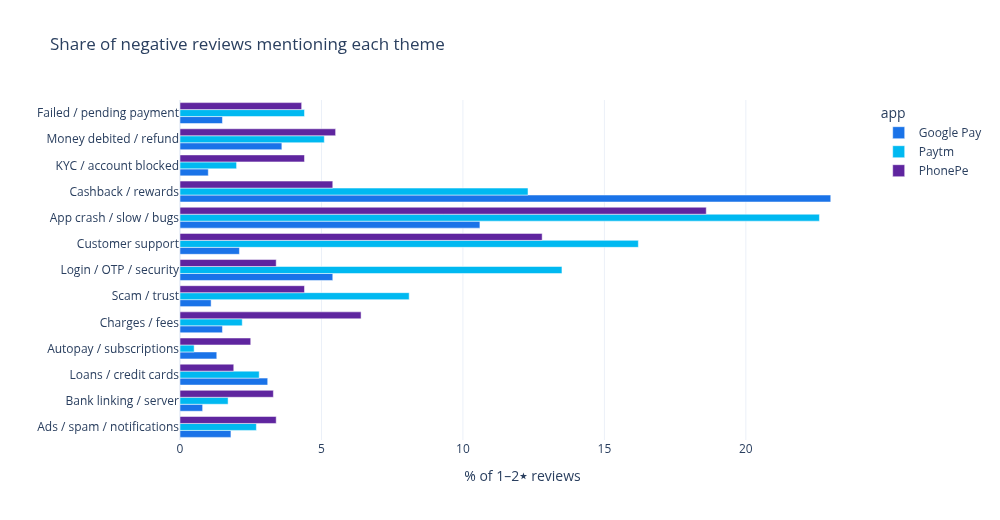

In [8]:
themes = run('complaint_themes')
save(px.bar(themes, y='theme', x='pct_of_negative', color='app', barmode='group', orientation='h',
            color_discrete_map=COLORS, category_orders={'theme': COMPLAINT_THEMES},
            title='Share of negative reviews mentioning each theme', labels={'pct_of_negative': '% of 1–2★ reviews', 'theme': ''}),
     'complaint_themes')

In [9]:
themes.pivot(index='theme', columns='app', values='pct_of_negative').sort_values('PhonePe', ascending=False)

app,Google Pay,Paytm,PhonePe
theme,,,
App crash / slow / bugs,10.6,22.6,18.6
Customer support,2.1,16.2,12.8
Charges / fees,1.5,2.2,6.4
Money debited / refund,3.6,5.1,5.5
Cashback / rewards,23.0,12.3,5.4
Scam / trust,1.1,8.1,4.4
KYC / account blocked,1.0,2.0,4.4
Failed / pending payment,1.5,4.4,4.3
Ads / spam / notifications,1.8,2.7,3.4


## 4. Which issues hurt the rating most?

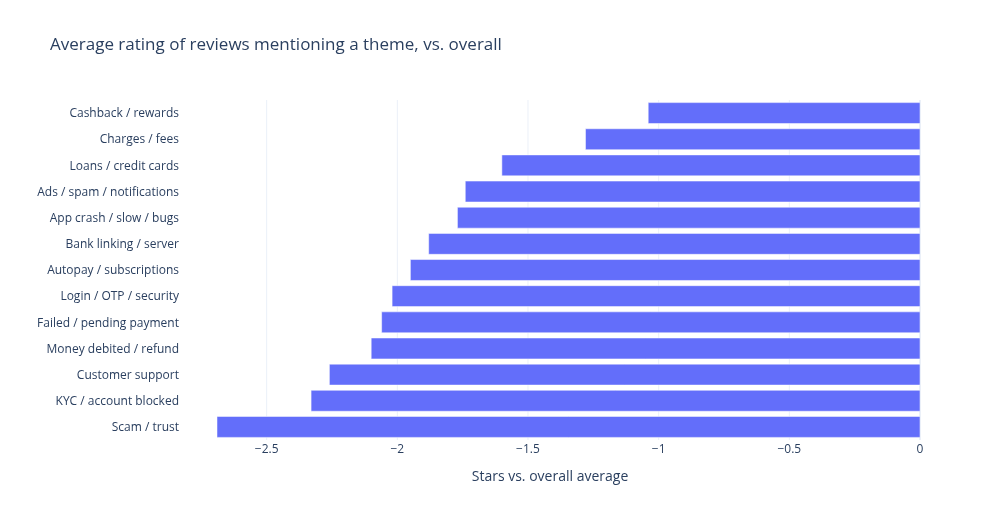

In [10]:
tr = run('theme_rating').query("theme != 'Praise'")
save(px.bar(tr, x='vs_overall', y='theme', orientation='h', title='Average rating of reviews mentioning a theme, vs. overall',
            labels={'vs_overall': 'Stars vs. overall average', 'theme': ''}), 'theme_rating')

## 5. App versions

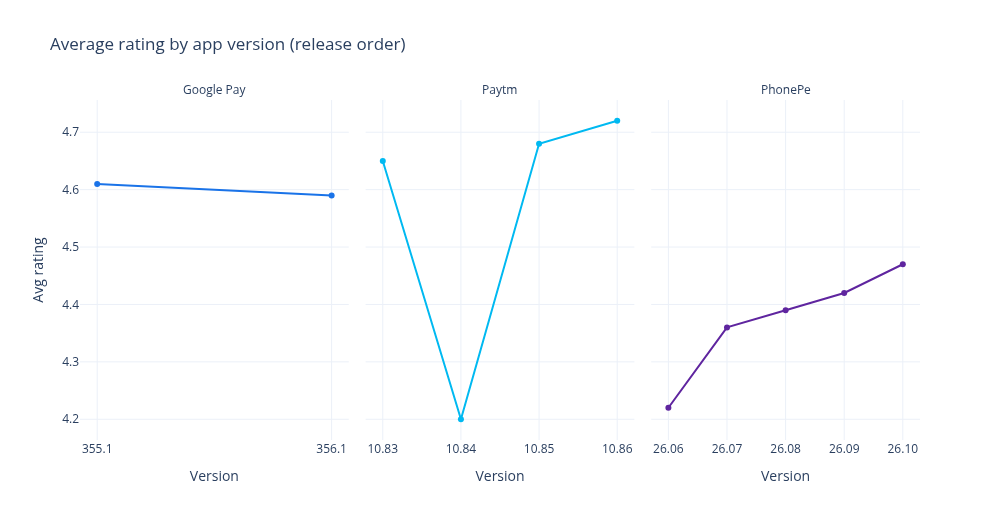

In [11]:
vr = run('version_ratings')
fig = px.line(vr, x='version_major', y='avg_rating', color='app', markers=True, facet_col='app',
              color_discrete_map=COLORS, title='Average rating by app version (release order)',
              labels={'version_major': 'Version', 'avg_rating': 'Avg rating'})
fig.update_xaxes(matches=None, type='category')
fig.for_each_annotation(lambda a: a.update(text=a.text.split('=')[-1]))
save(fig.update_layout(showlegend=False), 'version_ratings')

In [12]:
vr.sort_values('change_vs_prev').head(8)

,app,version_major,first_seen,reviews,avg_rating,change_vs_prev
3,Paytm,10.84,2026-09-04,2867,4.20,-0.45
1,Google Pay,356.1,2026-11-13,27031,4.59,-0.02
9,PhonePe,26.09,2026-09-22,10664,4.42,0.03
8,PhonePe,26.08,2026-09-17,3309,4.39,0.03
10,PhonePe,26.10,2026-10-19,8034,4.47,0.04
5,Paytm,10.86,2026-10-17,7305,4.72,0.04
7,PhonePe,26.07,2026-09-17,1165,4.36,0.14
4,Paytm,10.85,2026-09-16,10433,4.68,0.48


In [13]:
run('worst_version')

,app,version_major,reviews,avg_rating
0,Google Pay,356.1,27031,4.59
1,Paytm,10.84,2867,4.20
2,PhonePe,26.06,176,4.22


## 6. Developer responses

In [14]:
run('reply_stats')

,app,negative_reviews,pct_replied,median_reply_hours
0,Paytm,2781,93.6,0.6
1,PhonePe,3340,72.9,1.3
2,Google Pay,1749,17.7,0.3


## 7. Supporting checks

In [15]:
run('length_vs_rating')

,rating,reviews,avg_words
0,1,6535,13.9
1,2,1335,8.0
2,3,2872,4.3
3,4,8225,3.0
4,5,71033,2.5


In [16]:
run('top_liked_complaints')

,app,rating,thumbs_up,review_date,content
0,Google Pay,2,51,2026-11-15,The latest Google Pay update has broken accessibility for screen reader users specifically when checking the bank balance. Tapping 'Dismiss' causes the app ...
1,Google Pay,1,15,2026-11-13,"Very disappointing experience! I have been unable to check my bank balance on Google Pay for more than one month. Every time I enter my correct UPI PIN, it ..."
2,Google Pay,1,2,2026-11-19,I can't see the total monthly spend or earnings
3,Google Pay,1,2,2026-11-17,Signing Key Has Changed and Signing Certificate has been Rotated.This App Contains Several Pontentially Risky Elements like command Exucution vulnerability ...
4,Google Pay,1,2,2026-11-14,"I use some apps with accessibility permissions, and some other payment apps as well. This app is now demanding I disable accessibility permissions for those..."
5,Paytm,1,381,2026-09-09,"I had a very bad condition, The app was installed but it was not working properly, I did not open this app, please find the problem and solve it."
6,Paytm,1,191,2026-09-14,"I had a very disappointing experience with the service. There is no customer care number provided, and there appears to be no clear or convenient way to con..."
7,Paytm,1,150,2026-09-05,"What kind of payment system have you built? This has happened to me twice now—my payment showed as “Pending” for around 30 minutes, and then the money was d..."
8,Paytm,1,139,2026-09-17,"I have sent you mails many times about app not working, but it is matter of great concern that every time you send ( repeat) the same computerised message w..."
9,Paytm,1,89,2026-09-10,10/9/26 why paytm is not willing to share their customer care calling number or the email ID. a minor issue in the app is being dragged & paytm says my bank...


### Theme discovery check (TF-IDF + NMF)
To check the keyword taxonomy isn't missing a major issue, cluster untagged negative reviews and look at the top words.

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
with sqlite3.connect(DB_PATH) as con:
    untagged = pd.read_sql('''SELECT content FROM reviews r WHERE rating <= 2 AND is_english = 1 AND word_count >= 3
        AND NOT EXISTS (SELECT 1 FROM review_themes t WHERE t.review_id = r.review_id AND t.theme <> 'Praise')''', con)
print(f'{len(untagged):,} untagged negative reviews')
vec = TfidfVectorizer(stop_words='english', min_df=10, max_df=0.5, ngram_range=(1, 2))
X = vec.fit_transform(untagged['content'])
nmf = NMF(n_components=8, random_state=0).fit(X)
words = vec.get_feature_names_out()
for i, comp in enumerate(nmf.components_):
    print(i, ', '.join(words[comp.argsort()[-10:][::-1]]))

1,738 untagged negative reviews
0 app, bad app, nice, good app, open, use, update, open app, use app, upi app
1 bad, bad app, experience, bad experience, service, bad service, money, aap, poor, application
2 good, good app, service, work, ok, nice, pay, poor, rupees, aap
3 phone, pay, money, phone pay, account, time, google, google pay, pe, phone pe
4 hai, nhi, ho, raha, app hai, bahut, bekar, raha hai, nahi, ka
5 worst, worst app, upi, experience, service, seen, upi app, money, poor, worst experience
6 payment, time, payment app, update, add, upi, application, problem, make, phonepe
7 paytm, use, don, don use, phonepe, use app, open, paytm app, account, help


## Insights

1. **PhonePe has the lowest rating of the three.** In the dates all apps cover (14–19 Nov 2026), PhonePe averages **4.34★**, compared with 4.67★ for Paytm and 4.58★ for Google Pay. **10.5%** of its reviews are 1★, which is 2.4× Google Pay's 4.4%.
2. **Each app has a different main complaint.** In Google Pay's negative reviews, **cashback and rewards** come first (23%). Paytm's are about **crashes** (23%), **customer support** (16%) and **login/security-check errors** (14%). PhonePe has the highest share of **charges/fees** (6.4%, compared with 1.5–2.2%), **KYC/blocked accounts** (4.4%) and **bank linking** (3.3%).
3. **The most frequent complaints are not the most damaging.** Cashback complaints are common but mild (average **2.89★**). Reviews about **scams/trust (1.24★)**, **blocked accounts/KYC (1.60★)** and **customer support (1.67★)** have the lowest ratings: users who can't reach their money give 1★.
4. **One bad release can move the rating.** Paytm **10.84** dropped to **4.20★** (−0.45 from the previous version), and **41%** of its negative reviews were about crashes, compared with 23% for Paytm overall. The next version, 10.85, recovered to 4.68★. PhonePe's rating rose steadily across versions, from 4.36★ (26.07) to 4.47★ (26.10).
5. **Fees caused PhonePe's worst day.** On 18 Sep, PhonePe averaged **3.61★** with **31%** 1★ reviews, on about 35% more reviews than a normal day. Charges/fees were the top complaint that day (13% of negative reviews, compared with 6.4% normally), mostly about platform fees on recharges.

Supporting facts: Paytm replies to **94%** of negative reviews (median 0.6 h, so the replies are probably templated), PhonePe to 73% (1.3 h) and Google Pay to 18%. Unhappy users write about 5.5× more (13.9 words for a 1★ review, compared with 2.5 for a 5★).

## Recommendations (for PhonePe)
- **Show fees clearly before payment** (on the recharge checkout screen). Fee complaints are PhonePe's clearest point of difference from its competitors, and they caused its worst day.
- **Make blocked-account and KYC cases easier**: show the case status in the app and offer a human escalation path. These complaints are rarer but come with the lowest ratings.
- **Monitor crashes per release and roll out in stages**, as Paytm 10.84 shows what one bad release can do.
- **Measure whether replies solve the problem, not just how many reviews get one.**

## Limitations
- Play Store reviewers choose themselves, so these numbers show *what goes wrong*, not overall satisfaction.
- The sample is the latest 30k reviews per app, so Google Pay's covers only about 6 days. Cross-app ratings use the shared window only.
- Themes come from a keyword taxonomy on English/Hinglish text with at least 3 words. About **60%** of negative reviews get a specific theme; most of the rest are generic ("worst app"). A hand check of 50 reviews found the tags mostly correct.
- The theme spikes show what users said at the time; they don't prove the cause.
